In [1]:
!pip -q install "web3[tester]" py-solc-x pqcrypto cryptography pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.9/857.9 kB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 586.3/586.3 kB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.5/102.5 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.4/51.4 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 385.6/385.6 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.8/176.8 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 77.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 798.6/798.6 kB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/

In [2]:
import os

PROJECT = "/content/SBTAuth-FL"

folders = [
    PROJECT,
    f"{PROJECT}/contracts",
    f"{PROJECT}/src",
    f"{PROJECT}/experiments",
    f"{PROJECT}/results"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

open(f"{PROJECT}/src/__init__.py", "w").close()

print("Project created:")
for folder in folders:
    print(folder)

Project created:
/content/SBTAuth-FL
/content/SBTAuth-FL/contracts
/content/SBTAuth-FL/src
/content/SBTAuth-FL/experiments
/content/SBTAuth-FL/results


In [3]:
requirements = """web3[tester]
py-solc-x
pqcrypto
cryptography
pandas
matplotlib
"""

with open(f"{PROJECT}/requirements.txt", "w") as f:
    f.write(requirements)

print(open(f"{PROJECT}/requirements.txt").read())

web3[tester]
py-solc-x
pqcrypto
cryptography
pandas
matplotlib



In [4]:
solidity_code = r'''
// SPDX-License-Identifier: MIT
pragma solidity ^0.8.24;

contract SBTRegistry {

    address public immutable registrar;

    enum Status {
        Invalid,
        Valid,
        Revoked
    }

    enum EntityType {
        None,
        Hospital,
        FLS
    }

    struct Credential {
        bytes32 tokenID;
        bytes32 did;
        address owner;
        bytes32 vcHash;
        bytes pqcPublicKey;
        uint256 expiry;
        Status status;
        EntityType entityType;
    }

    mapping(bytes32 => Credential) private credentials;

    event CredentialRegistered(
        bytes32 indexed tokenID,
        bytes32 indexed did,
        address indexed owner,
        EntityType entityType
    );

    event CredentialRevoked(bytes32 indexed tokenID);

    modifier onlyRegistrar() {
        require(msg.sender == registrar, "Unauthorized registrar");
        _;
    }

    constructor() {
        registrar = msg.sender;
    }

    function registerHospital(
        bytes32 tokenID,
        bytes32 did,
        address owner,
        bytes32 vcHash,
        bytes calldata pqcPublicKey,
        uint256 expiry
    ) external onlyRegistrar {

        require(credentials[tokenID].status == Status.Invalid,
                "Token already exists");

        credentials[tokenID] = Credential(
            tokenID,
            did,
            owner,
            vcHash,
            pqcPublicKey,
            expiry,
            Status.Valid,
            EntityType.Hospital
        );

        emit CredentialRegistered(
            tokenID,
            did,
            owner,
            EntityType.Hospital
        );
    }

    function registerFLS(
        bytes32 tokenID,
        bytes32 did,
        address owner,
        bytes32 vcHash,
        bytes calldata pqcPublicKey,
        uint256 expiry
    ) external onlyRegistrar {

        require(credentials[tokenID].status == Status.Invalid,
                "Token already exists");

        credentials[tokenID] = Credential(
            tokenID,
            did,
            owner,
            vcHash,
            pqcPublicKey,
            expiry,
            Status.Valid,
            EntityType.FLS
        );

        emit CredentialRegistered(
            tokenID,
            did,
            owner,
            EntityType.FLS
        );
    }

    function verifyHospital(bytes32 tokenID)
        external
        view
        returns (
            bool valid,
            bytes memory pqcPublicKey,
            address owner
        )
    {
        Credential storage c = credentials[tokenID];

        bool ok =
            c.status == Status.Valid &&
            c.entityType == EntityType.Hospital &&
            c.expiry >= block.timestamp;

        return (ok, c.pqcPublicKey, c.owner);
    }

    function verifyFLS(
        bytes32 did,
        bytes32 tokenID
    )
        external
        view
        returns (
            bool valid,
            bytes memory pqcPublicKey,
            address owner
        )
    {
        Credential storage c = credentials[tokenID];

        bool ok =
            c.status == Status.Valid &&
            c.entityType == EntityType.FLS &&
            c.did == did &&
            c.expiry >= block.timestamp;

        return (ok, c.pqcPublicKey, c.owner);
    }

    function revokeSBT(bytes32 tokenID)
        external
        onlyRegistrar
    {
        require(
            credentials[tokenID].status == Status.Valid,
            "Credential not valid"
        );

        credentials[tokenID].status = Status.Revoked;

        emit CredentialRevoked(tokenID);
    }

    function getCredential(bytes32 tokenID)
        external
        view
        returns (
            bytes32 did,
            address owner,
            bytes32 vcHash,
            bytes memory pqcPublicKey,
            uint256 expiry,
            Status status,
            EntityType entityType
        )
    {
        Credential storage c = credentials[tokenID];

        return (
            c.did,
            c.owner,
            c.vcHash,
            c.pqcPublicKey,
            c.expiry,
            c.status,
            c.entityType
        );
    }
}
'''

with open(f"{PROJECT}/contracts/SBTRegistry.sol", "w") as f:
    f.write(solidity_code)

print("Smart contract created.")

Smart contract created.


In [5]:
from solcx import install_solc, set_solc_version, compile_source

SOLC_VERSION = "0.8.24"

install_solc(SOLC_VERSION)
set_solc_version(SOLC_VERSION)

with open(f"{PROJECT}/contracts/SBTRegistry.sol") as f:
    contract_source = f.read()

compiled = compile_source(
    contract_source,
    output_values=["abi", "bin"],
    solc_version=SOLC_VERSION
)

contract_id, contract_interface = compiled.popitem()

ABI = contract_interface["abi"]
BYTECODE = contract_interface["bin"]

print("Solidity contract compiled successfully.")

Solidity contract compiled successfully.


In [6]:
from web3 import Web3, EthereumTesterProvider

w3 = Web3(EthereumTesterProvider())

assert w3.is_connected()

accounts = w3.eth.accounts

RA_CHAIN_ACCOUNT = accounts[0]

print("Blockchain connected:", w3.is_connected())
print("RA blockchain account:", RA_CHAIN_ACCOUNT)
print("Available validator/test accounts:", len(accounts))

Blockchain connected: True
RA blockchain account: 0x7E5F4552091A69125d5DfCb7b8C2659029395Bdf
Available validator/test accounts: 10


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [7]:
SBTRegistry = w3.eth.contract(
    abi=ABI,
    bytecode=BYTECODE
)

tx_hash = SBTRegistry.constructor().transact({
    "from": RA_CHAIN_ACCOUNT
})

receipt = w3.eth.wait_for_transaction_receipt(tx_hash)

contract = w3.eth.contract(
    address=receipt.contractAddress,
    abi=ABI
)

print("SBTRegistry deployed.")
print("Contract address:", receipt.contractAddress)
print("Block number:", receipt.blockNumber)

SBTRegistry deployed.
Contract address: 0xF2E246BB76DF876Cef8b38ae84130F4F55De395b
Block number: 1


In [8]:
from hashlib import sha256
import secrets
import json

from pqcrypto.sign.ml_dsa_44 import (
    keygen as mldsa_keygen,
    sign as mldsa_sign,
    verify as mldsa_verify
)

from cryptography.hazmat.primitives.asymmetric import ec
from cryptography.hazmat.primitives import serialization


def to_bytes(value):
    if isinstance(value, bytes):
        return value
    if isinstance(value, str):
        return value.encode("utf-8")
    if isinstance(value, int):
        return value.to_bytes(
            max(1, (value.bit_length() + 7) // 8),
            "big"
        )
    raise TypeError(f"Unsupported type: {type(value)}")


def H(*values):
    """
    Implementation of h(A || B || ...).
    Length-separated encoding avoids ambiguity.
    """
    encoded = b""

    for value in values:
        value = to_bytes(value)
        encoded += len(value).to_bytes(4, "big") + value

    return sha256(encoded).digest()


def random_nonce(size=32):
    return secrets.token_bytes(size)


def random_token_id():
    return secrets.token_bytes(32)


def generate_pqc_keypair():
    pk, sk = mldsa_keygen()
    return pk, sk


def pqc_sign(sk, message):
    return mldsa_sign(sk, message)


def pqc_verify(pk, message, signature):
    try:
        result = mldsa_verify(pk, message, signature)

        # Different pqcrypto releases may return None or True
        return result is None or result is True
    except Exception:
        return False


def generate_ecdh_keypair():
    private_key = ec.generate_private_key(ec.SECP256R1())

    public_key = private_key.public_key()

    public_bytes = public_key.public_bytes(
        encoding=serialization.Encoding.X962,
        format=serialization.PublicFormat.UncompressedPoint
    )

    return private_key, public_bytes


def ecdh_shared_secret(private_key, peer_public_bytes):
    peer_public_key = ec.EllipticCurvePublicKey.from_encoded_point(
        ec.SECP256R1(),
        peer_public_bytes
    )

    return private_key.exchange(
        ec.ECDH(),
        peer_public_key
    )


print("Cryptographic utilities loaded.")

Cryptographic utilities loaded.


In [9]:
pk_test, sk_test = generate_pqc_keypair()

msg_test = b"SBTAuth-FL test"

sig_test = pqc_sign(sk_test, msg_test)

print("ML-DSA-44 public key :", len(pk_test), "bytes")
print("ML-DSA-44 private key:", len(sk_test), "bytes")
print("ML-DSA-44 signature  :", len(sig_test), "bytes")
print("Signature valid      :", pqc_verify(pk_test, msg_test, sig_test))

ML-DSA-44 public key : 1312 bytes
ML-DSA-44 private key: 2560 bytes
ML-DSA-44 signature  : 2420 bytes
Signature valid      : True


In [10]:
x_RA = secrets.token_bytes(32)

print("RA initialized.")
print("x_RA length:", len(x_RA), "bytes")

RA initialized.
x_RA length: 32 bytes


In [11]:
from eth_account import Account

hospital_bc = Account.create()
fls_bc = Account.create()

Owner_i = hospital_bc.address
Owner_F = fls_bc.address

print("Hospital Owner_i:", Owner_i)
print("FLS Owner_F     :", Owner_F)

Hospital Owner_i: 0xA7Fa4d040168aE0C3e313A6c129f2327A8dE4FE2
FLS Owner_F     : 0xF0B6575f67812301BB75DD3763e4BB4b957AcAaD


In [12]:
ID_i = "Hospital-A"

pk_i, sk_i = generate_pqc_keypair()

print("Hospital:", ID_i)
print("PQC public key bytes:", len(pk_i))

Hospital: Hospital-A
PQC public key bytes: 1312


In [13]:
import time

DID_i = H(ID_i, x_RA)
PID_i = H(DID_i, x_RA)

expiry_i = int(time.time()) + 365 * 24 * 60 * 60

VC_i = {
    "PID": PID_i.hex(),
    "Role": "HealthcareInstitution",
    "Hospital": "Hospital-A",
    "AccessLevel": "FL_PARTICIPANT",
    "Expiry": expiry_i
}

VC_i_bytes = json.dumps(
    VC_i,
    sort_keys=True,
    separators=(",", ":")
).encode()

VC_i_hash = sha256(VC_i_bytes).digest()

TokenID_i = random_token_id()

print("DID_i     :", DID_i.hex()[:32] + "...")
print("PID_i     :", PID_i.hex()[:32] + "...")
print("TokenID_i :", TokenID_i.hex())
print("VC hash   :", VC_i_hash.hex())

DID_i     : d1078038986315dc9d046b13d729bca6...
PID_i     : c0525761a3eff86e34bed0794aff174a...
TokenID_i : 238d49f714d228216061a45d0c74c2d14c6015524b201ff4f4b072f6e1c22b8b
VC hash   : d817a0a742a87c481677c29466132285691b7c2e14aa9ba52675b763f2cda1a1


In [14]:
tx = contract.functions.registerHospital(
    TokenID_i,
    DID_i,
    Owner_i,
    VC_i_hash,
    pk_i,
    expiry_i
).transact({
    "from": RA_CHAIN_ACCOUNT
})

receipt_h = w3.eth.wait_for_transaction_receipt(tx)

print("Hospital SBT registered.")
print("Transaction:", receipt_h.transactionHash.hex())
print("Block:", receipt_h.blockNumber)
print("Gas used:", receipt_h.gasUsed)

Hospital SBT registered.
Transaction: a3bf04e805ae2b61fd0b81f69b8f18c37be84331ea2ff631c8744bb52acae093
Block: 2
Gas used: 1115095


In [15]:
record_h = contract.functions.getCredential(
    TokenID_i
).call()

print("Hospital blockchain record")
print("--------------------------")
print("DID matches :", record_h[0] == DID_i)
print("Owner       :", record_h[1])
print("VC hash     :", record_h[2].hex())
print("PQC PK size :", len(record_h[3]), "bytes")
print("Expiry      :", record_h[4])
print("Status      :", record_h[5])
print("Entity type :", record_h[6])

Hospital blockchain record
--------------------------
DID matches : True
Owner       : 0xA7Fa4d040168aE0C3e313A6c129f2327A8dE4FE2
VC hash     : d817a0a742a87c481677c29466132285691b7c2e14aa9ba52675b763f2cda1a1
PQC PK size : 1312 bytes
Expiry      : 1820308162
Status      : 1
Entity type : 1


In [16]:
ID_F = "Federated-Learning-Server"

pk_F, sk_F = generate_pqc_keypair()

DID_F = H(ID_F, x_RA)

expiry_F = int(time.time()) + 365 * 24 * 60 * 60

VC_F = {
    "DID": DID_F.hex(),
    "Role": "FederatedLearningServer",
    "Service": "Healthcare-FL",
    "Expiry": expiry_F
}

VC_F_bytes = json.dumps(
    VC_F,
    sort_keys=True,
    separators=(",", ":")
).encode()

VC_F_hash = sha256(VC_F_bytes).digest()

TokenID_F = random_token_id()

tx = contract.functions.registerFLS(
    TokenID_F,
    DID_F,
    Owner_F,
    VC_F_hash,
    pk_F,
    expiry_F
).transact({
    "from": RA_CHAIN_ACCOUNT
})

receipt_f = w3.eth.wait_for_transaction_receipt(tx)

print("FLS registered.")
print("DID_F     :", DID_F.hex()[:32] + "...")
print("TokenID_F :", TokenID_F.hex())
print("Gas used  :", receipt_f.gasUsed)

FLS registered.
DID_F     : 1ec5362863bd7f002631fd831776d1ed...
TokenID_F : 9edadbc761a841787dfefa3d481b1c83893f470d4aa908d2ecf81436fd74a802
Gas used  : 1114986


In [17]:
a_private, X_i = generate_ecdh_keypair()

N1 = random_nonce()

SPID_i = H(PID_i, N1)

M1 = H(
    SPID_i,
    TokenID_i,
    X_i,
    N1
)

sigma_i = pqc_sign(
    sk_i,
    M1
)

request_H_to_FLS = {
    "SPID_i": SPID_i,
    "TokenID_i": TokenID_i,
    "X_i": X_i,
    "N1": N1,
    "M1": M1,
    "sigma_i": sigma_i
}

print("Authentication request generated.")
print("SPID_i size :", len(SPID_i))
print("X_i size    :", len(X_i))
print("N1 size     :", len(N1))
print("M1 size     :", len(M1))
print("sigma_i size:", len(sigma_i))

Authentication request generated.
SPID_i size : 32
X_i size    : 65
N1 size     : 32
M1 size     : 32
sigma_i size: 2420


In [18]:
valid_h, registered_pk_i, registered_owner_i = \
    contract.functions.verifyHospital(
        request_H_to_FLS["TokenID_i"]
    ).call()

print("Hospital credential valid:", valid_h)
print("Owner:", registered_owner_i)

assert valid_h, "Hospital SBT is invalid/revoked/expired."
assert registered_pk_i == pk_i

print("Blockchain hospital verification PASSED.")

Hospital credential valid: True
Owner: 0xA7Fa4d040168aE0C3e313A6c129f2327A8dE4FE2
Blockchain hospital verification PASSED.


In [19]:
used_N1 = set()

received_N1_hex = request_H_to_FLS["N1"].hex()

if received_N1_hex in used_N1:
    raise ValueError("Replay attack detected: N1 already used.")

M1_star = H(
    request_H_to_FLS["SPID_i"],
    request_H_to_FLS["TokenID_i"],
    request_H_to_FLS["X_i"],
    request_H_to_FLS["N1"]
)

assert M1_star == request_H_to_FLS["M1"], \
    "M1 integrity verification failed."

assert pqc_verify(
    registered_pk_i,
    request_H_to_FLS["M1"],
    request_H_to_FLS["sigma_i"]
), "Hospital PQC signature verification failed."

used_N1.add(received_N1_hex)

print("Hospital authenticated successfully.")

Hospital authenticated successfully.


In [20]:
b_private, Y_F = generate_ecdh_keypair()

N2 = random_nonce()

K_F = ecdh_shared_secret(
    b_private,
    X_i
)

M2 = H(
    DID_F,
    TokenID_F,
    SPID_i,
    X_i,
    Y_F,
    N1,
    N2
)

sigma_F = pqc_sign(
    sk_F,
    M2
)

response_FLS_to_H = {
    "DID_F": DID_F,
    "TokenID_F": TokenID_F,
    "Y_F": Y_F,
    "N2": N2,
    "M2": M2,
    "sigma_F": sigma_F
}

print("FLS response generated.")
print("Y_F size     :", len(Y_F))
print("N2 size      :", len(N2))
print("M2 size      :", len(M2))
print("sigma_F size :", len(sigma_F))

FLS response generated.
Y_F size     : 65
N2 size      : 32
M2 size      : 32
sigma_F size : 2420


In [21]:
valid_f, registered_pk_F, registered_owner_F = \
    contract.functions.verifyFLS(
        response_FLS_to_H["DID_F"],
        response_FLS_to_H["TokenID_F"]
    ).call()

assert valid_f, "FLS credential invalid/revoked/expired."
assert registered_pk_F == pk_F

print("FLS blockchain credential verification PASSED.")
print("Registered Owner_F:", registered_owner_F)

FLS blockchain credential verification PASSED.
Registered Owner_F: 0xF0B6575f67812301BB75DD3763e4BB4b957AcAaD


In [22]:
M2_star = H(
    response_FLS_to_H["DID_F"],
    response_FLS_to_H["TokenID_F"],
    SPID_i,
    X_i,
    response_FLS_to_H["Y_F"],
    N1,
    response_FLS_to_H["N2"]
)

assert M2_star == response_FLS_to_H["M2"], \
    "M2 integrity check failed."

assert pqc_verify(
    registered_pk_F,
    response_FLS_to_H["M2"],
    response_FLS_to_H["sigma_F"]
), "FLS PQC signature verification failed."

print("FLS authenticated successfully.")

FLS authenticated successfully.


In [23]:
K_i = ecdh_shared_secret(
    a_private,
    response_FLS_to_H["Y_F"]
)

print("ECDH agreement:", K_i == K_F)

assert K_i == K_F

ECDH agreement: True


In [24]:
SK_H = H(
    K_i,
    SPID_i,
    TokenID_i,
    TokenID_F,
    X_i,
    Y_F,
    N1,
    N2
)

SK_F = H(
    K_F,
    SPID_i,
    TokenID_i,
    TokenID_F,
    X_i,
    Y_F,
    N1,
    N2
)

assert SK_H == SK_F

print("SESSION ESTABLISHED")
print("Session keys equal:", SK_H == SK_F)
print("SK length:", len(SK_H), "bytes")
print("SK:", SK_H.hex())

SESSION ESTABLISHED
Session keys equal: True
SK length: 32 bytes
SK: a247f8cee4aea4d6fdb902573b8459f5c366580312d06ac2698366f1f755d6ac


In [25]:
print("""
==================================================
             SBTAuth-FL PoC Result
==================================================
1. Hospital registration       : PASS
2. FLS registration            : PASS
3. Hospital SBT verification   : PASS
4. Hospital PQC authentication : PASS
5. FLS SBT verification        : PASS
6. FLS PQC authentication      : PASS
7. Mutual authentication       : PASS
8. ECDH key agreement          : PASS
9. Session-key agreement       : PASS
10. FL authorization           : GRANTED
==================================================
""")


             SBTAuth-FL PoC Result
1. Hospital registration       : PASS
2. FLS registration            : PASS
3. Hospital SBT verification   : PASS
4. Hospital PQC authentication : PASS
5. FLS SBT verification        : PASS
6. FLS PQC authentication      : PASS
7. Mutual authentication       : PASS
8. ECDH key agreement          : PASS
9. Session-key agreement       : PASS
10. FL authorization           : GRANTED



In [26]:
attacker_pk, attacker_sk = generate_pqc_keypair()

forged_M1 = H(
    SPID_i,
    TokenID_i,
    X_i,
    N1
)

forged_sigma = pqc_sign(
    attacker_sk,
    forged_M1
)

attack_success = pqc_verify(
    registered_pk_i,
    forged_M1,
    forged_sigma
)

print("Attacker signature accepted:", attack_success)

assert attack_success is False

print("Hospital impersonation attack BLOCKED.")

Attacker signature accepted: False
Hospital impersonation attack BLOCKED.


In [27]:
fake_fls_pk, fake_fls_sk = generate_pqc_keypair()

fake_b, fake_Y = generate_ecdh_keypair()

fake_M2 = H(
    DID_F,
    TokenID_F,
    SPID_i,
    X_i,
    fake_Y,
    N1,
    N2
)

fake_sigma_F = pqc_sign(
    fake_fls_sk,
    fake_M2
)

accepted = pqc_verify(
    registered_pk_F,
    fake_M2,
    fake_sigma_F
)

print("Fake FLS accepted:", accepted)

assert accepted is False

print("FLS impersonation attack BLOCKED.")

Fake FLS accepted: False
FLS impersonation attack BLOCKED.


In [28]:
_, attacker_Y = generate_ecdh_keypair()

tampered_M2_star = H(
    DID_F,
    TokenID_F,
    SPID_i,
    X_i,
    attacker_Y,       # attacker substituted Y_F
    N1,
    N2
)

mitm_accepted = (
    tampered_M2_star == M2
    and pqc_verify(pk_F, M2, sigma_F)
)

print("Tampered Y_F accepted:", mitm_accepted)

assert mitm_accepted is False

print("MITM key-substitution attack BLOCKED.")

Tampered Y_F accepted: False
MITM key-substitution attack BLOCKED.


In [29]:
seen_nonces = set()

def accept_nonce(nonce):
    key = nonce.hex()

    if key in seen_nonces:
        return False

    seen_nonces.add(key)
    return True


first_attempt = accept_nonce(N1)
replay_attempt = accept_nonce(N1)

print("Original message accepted:", first_attempt)
print("Replayed message accepted:", replay_attempt)

assert first_attempt is True
assert replay_attempt is False

print("Replay attack BLOCKED.")

Original message accepted: True
Replayed message accepted: False
Replay attack BLOCKED.


In [30]:
import time
import statistics

ITERATIONS = 100

keygen_times = []
sign_times = []
verify_times = []

message = H(b"SBTAuth-FL benchmark message")

for _ in range(ITERATIONS):

    t0 = time.perf_counter()
    pk_b, sk_b = generate_pqc_keypair()
    keygen_times.append(
        (time.perf_counter() - t0) * 1000
    )

    t0 = time.perf_counter()
    sig_b = pqc_sign(sk_b, message)
    sign_times.append(
        (time.perf_counter() - t0) * 1000
    )

    t0 = time.perf_counter()
    valid = pqc_verify(pk_b, message, sig_b)
    verify_times.append(
        (time.perf_counter() - t0) * 1000
    )

    assert valid


print("ML-DSA-44 benchmark")
print("--------------------")
print("KeyGen :", statistics.mean(keygen_times), "ms")
print("Sign   :", statistics.mean(sign_times), "ms")
print("Verify :", statistics.mean(verify_times), "ms")

ML-DSA-44 benchmark
--------------------
KeyGen : 0.41094531998624007 ms
Sign   : 22.919983680012592 ms
Verify : 0.5207200100062437 ms


In [31]:
ecdh_keygen_times = []
ecdh_shared_times = []

for _ in range(ITERATIONS):

    t0 = time.perf_counter()

    a_bench, A_bench = generate_ecdh_keypair()
    b_bench, B_bench = generate_ecdh_keypair()

    ecdh_keygen_times.append(
        (time.perf_counter() - t0) * 1000
    )

    t0 = time.perf_counter()

    KA = ecdh_shared_secret(
        a_bench,
        B_bench
    )

    KB = ecdh_shared_secret(
        b_bench,
        A_bench
    )

    ecdh_shared_times.append(
        (time.perf_counter() - t0) * 1000
    )

    assert KA == KB


print("ECDH benchmark")
print("--------------")
print(
    "Two ephemeral key generations:",
    statistics.mean(ecdh_keygen_times),
    "ms"
)
print(
    "Two shared-secret computations:",
    statistics.mean(ecdh_shared_times),
    "ms"
)

ECDH benchmark
--------------
Two ephemeral key generations: 0.08276733999082353 ms
Two shared-secret computations: 0.24089914000342105 ms


In [32]:
M1_message_size = (
    len(SPID_i)
    + len(TokenID_i)
    + len(X_i)
    + len(N1)
    + len(M1)
    + len(sigma_i)
)

M2_message_size = (
    len(DID_F)
    + len(TokenID_F)
    + len(Y_F)
    + len(N2)
    + len(M2)
    + len(sigma_F)
)

total_auth_comm = (
    M1_message_size +
    M2_message_size
)

print("Message 1 :", M1_message_size, "bytes")
print("Message 2 :", M2_message_size, "bytes")
print("Total     :", total_auth_comm, "bytes")
print(
    "Total     :",
    total_auth_comm * 8,
    "bits"
)

Message 1 : 2613 bytes
Message 2 : 2613 bytes
Total     : 5226 bytes
Total     : 41808 bits


In [33]:
import pandas as pd

results = pd.DataFrame([
    {
        "Operation": "ML-DSA-44 KeyGen",
        "Mean_ms": statistics.mean(keygen_times)
    },
    {
        "Operation": "ML-DSA-44 Sign",
        "Mean_ms": statistics.mean(sign_times)
    },
    {
        "Operation": "ML-DSA-44 Verify",
        "Mean_ms": statistics.mean(verify_times)
    },
    {
        "Operation": "ECDH Key Generation (2 parties)",
        "Mean_ms": statistics.mean(ecdh_keygen_times)
    },
    {
        "Operation": "ECDH Shared Secret (2 parties)",
        "Mean_ms": statistics.mean(ecdh_shared_times)
    }
])

results.to_csv(
    f"{PROJECT}/results/crypto_benchmark.csv",
    index=False
)

results

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Operation,Mean_ms
0,ML-DSA-44 KeyGen,0.410945
1,ML-DSA-44 Sign,22.919984
2,ML-DSA-44 Verify,0.520720
3,ECDH Key Generation (2 parties),0.082767
4,ECDH Shared Secret (2 parties),0.240899


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [34]:
print("Hospital registration gas:",
      receipt_h.gasUsed)

print("FLS registration gas:",
      receipt_f.gasUsed)

print("Hospital registration block:",
      receipt_h.blockNumber)

print("FLS registration block:",
      receipt_f.blockNumber)

Hospital registration gas: 1115095
FLS registration gas: 1114986
Hospital registration block: 2
FLS registration block: 3


In [35]:
def authorize_fl_participation(
    token_id,
    signature_valid
):
    valid, _, _ = \
        contract.functions.verifyHospital(
            token_id
        ).call()

    return valid and signature_valid


# This will be False if Cell 30 revocation was already run.
authorized = authorize_fl_participation(
    TokenID_i,
    True
)

print("FL participation authorized:", authorized)

FL participation authorized: True


In [36]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cpu


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [37]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root=f"{PROJECT}/data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root=f"{PROJECT}/data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 487kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.49MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.6MB/s]

Training samples: 60000
Test samples: 10000


In [38]:
class SimpleCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            1, 16,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(2)

        self.conv2 = nn.Conv2d(
            16, 32,
            kernel_size=3,
            padding=1
        )

        self.fc1 = nn.Linear(
            32 * 7 * 7,
            64
        )

        self.fc2 = nn.Linear(
            64,
            10
        )

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.pool(
            self.relu(self.conv1(x))
        )

        x = self.pool(
            self.relu(self.conv2(x))
        )

        x = x.view(x.size(0), -1)

        x = self.relu(
            self.fc1(x)
        )

        return self.fc2(x)


global_model = SimpleCNN()

print(global_model)

SimpleCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=1568, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)


In [39]:
import numpy as np

NUM_CLIENTS = 20

indices = np.random.permutation(
    len(train_dataset)
)

client_indices = np.array_split(
    indices,
    NUM_CLIENTS
)

print(
    "Samples per client:",
    [len(x) for x in client_indices[:5]]
)

Samples per client: [3000, 3000, 3000, 3000, 3000]


In [40]:
import copy

def train_local_model(
    global_model,
    dataset,
    indices,
    epochs=1,
    batch_size=64,
    lr=0.01
):

    model = copy.deepcopy(global_model)

    loader = DataLoader(
        Subset(dataset, indices),
        batch_size=batch_size,
        shuffle=True
    )

    optimizer = optim.SGD(
        model.parameters(),
        lr=lr
    )

    criterion = nn.CrossEntropyLoss()

    model.train()

    for _ in range(epochs):

        for data, target in loader:

            optimizer.zero_grad()

            output = model(data)

            loss = criterion(
                output,
                target
            )

            loss.backward()

            optimizer.step()

    return model.state_dict()

In [41]:
def fedavg(local_states):

    avg_state = copy.deepcopy(
        local_states[0]
    )

    for key in avg_state.keys():

        avg_state[key] = sum(
            state[key]
            for state in local_states
        ) / len(local_states)

    return avg_state

In [42]:
def evaluate(model, dataset):

    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False
    )

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for data, target in loader:

            output = model(data)

            pred = output.argmax(
                dim=1
            )

            correct += (
                pred == target
            ).sum().item()

            total += target.size(0)

    return 100.0 * correct / total

In [43]:
CLIENTS_PER_ROUND = 10

selected_clients = np.random.choice(
    NUM_CLIENTS,
    CLIENTS_PER_ROUND,
    replace=False
)

local_updates = []

for client_id in selected_clients:

    # In the full experiment each client gets its own TokenID.
    # Here we demonstrate the authentication gate.
    credential_valid, _, _ = \
        contract.functions.verifyHospital(
            TokenID_i
        ).call()

    if not credential_valid:
        print(
            f"Client {client_id}: rejected"
        )
        continue

    state = train_local_model(
        global_model,
        train_dataset,
        client_indices[client_id],
        epochs=1
    )

    local_updates.append(state)

    print(
        f"Client {client_id}: authenticated "
        "and update accepted"
    )


if local_updates:

    averaged_state = fedavg(
        local_updates
    )

    global_model.load_state_dict(
        averaged_state
    )

    accuracy = evaluate(
        global_model,
        test_dataset
    )

    print(
        "Global accuracy:",
        accuracy
    )

Client 2: authenticated and update accepted
Client 14: authenticated and update accepted
Client 4: authenticated and update accepted
Client 11: authenticated and update accepted
Client 17: authenticated and update accepted
Client 13: authenticated and update accepted
Client 10: authenticated and update accepted
Client 3: authenticated and update accepted
Client 9: authenticated and update accepted
Client 5: authenticated and update accepted
Global accuracy: 44.41


In [44]:
import os
import pandas as pd
import numpy as np
import time
import statistics

RESULTS_DIR = f"{PROJECT}/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Results folder:", RESULTS_DIR)

Results folder: /content/SBTAuth-FL/results


In [45]:
ITERATIONS = 100

keygen_times = []
sign_times = []
verify_times = []
ecdh_keygen_times = []
ecdh_shared_times = []
hash_times = []

benchmark_message = H(b"SBTAuth-FL benchmark")

for _ in range(ITERATIONS):

    # ML-DSA key generation
    t0 = time.perf_counter()
    pk_b, sk_b = generate_pqc_keypair()
    keygen_times.append((time.perf_counter() - t0) * 1000)

    # ML-DSA signing
    t0 = time.perf_counter()
    sig_b = pqc_sign(sk_b, benchmark_message)
    sign_times.append((time.perf_counter() - t0) * 1000)

    # ML-DSA verification
    t0 = time.perf_counter()
    valid = pqc_verify(pk_b, benchmark_message, sig_b)
    verify_times.append((time.perf_counter() - t0) * 1000)

    assert valid

    # ECDH key generation
    t0 = time.perf_counter()
    a_b, A_b = generate_ecdh_keypair()
    b_b, B_b = generate_ecdh_keypair()
    ecdh_keygen_times.append((time.perf_counter() - t0) * 1000)

    # ECDH shared-secret generation
    t0 = time.perf_counter()
    KA = ecdh_shared_secret(a_b, B_b)
    KB = ecdh_shared_secret(b_b, A_b)
    ecdh_shared_times.append((time.perf_counter() - t0) * 1000)

    assert KA == KB

    # Hash
    t0 = time.perf_counter()
    _ = H(benchmark_message, sig_b[:32])
    hash_times.append((time.perf_counter() - t0) * 1000)


crypto_results = pd.DataFrame([
    {
        "Operation": "ML-DSA-44 KeyGen",
        "Mean_ms": np.mean(keygen_times),
        "Std_ms": np.std(keygen_times),
        "Min_ms": np.min(keygen_times),
        "Max_ms": np.max(keygen_times)
    },
    {
        "Operation": "ML-DSA-44 Sign",
        "Mean_ms": np.mean(sign_times),
        "Std_ms": np.std(sign_times),
        "Min_ms": np.min(sign_times),
        "Max_ms": np.max(sign_times)
    },
    {
        "Operation": "ML-DSA-44 Verify",
        "Mean_ms": np.mean(verify_times),
        "Std_ms": np.std(verify_times),
        "Min_ms": np.min(verify_times),
        "Max_ms": np.max(verify_times)
    },
    {
        "Operation": "ECDH KeyGen (2 parties)",
        "Mean_ms": np.mean(ecdh_keygen_times),
        "Std_ms": np.std(ecdh_keygen_times),
        "Min_ms": np.min(ecdh_keygen_times),
        "Max_ms": np.max(ecdh_keygen_times)
    },
    {
        "Operation": "ECDH Shared Secret (2 parties)",
        "Mean_ms": np.mean(ecdh_shared_times),
        "Std_ms": np.std(ecdh_shared_times),
        "Min_ms": np.min(ecdh_shared_times),
        "Max_ms": np.max(ecdh_shared_times)
    },
    {
        "Operation": "SHA-256 Transcript Hash",
        "Mean_ms": np.mean(hash_times),
        "Std_ms": np.std(hash_times),
        "Min_ms": np.min(hash_times),
        "Max_ms": np.max(hash_times)
    }
])

crypto_path = f"{RESULTS_DIR}/crypto_benchmark.csv"
crypto_results.to_csv(crypto_path, index=False)

print("Saved:", crypto_path)
display(crypto_results)

Saved: /content/SBTAuth-FL/results/crypto_benchmark.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Operation,Mean_ms,Std_ms,Min_ms,Max_ms
0,ML-DSA-44 KeyGen,0.705560,1.029620,0.237758,6.401409
1,ML-DSA-44 Sign,32.418073,18.325687,11.030167,93.554426
2,ML-DSA-44 Verify,0.745931,1.572376,0.232122,13.396975
3,ECDH KeyGen (2 parties),0.476770,0.699489,0.203581,6.434418
4,ECDH Shared Secret (2 parties),0.832975,1.384970,0.244430,10.052580
5,SHA-256 Transcript Hash,0.091481,0.361726,0.026883,3.074158


In [46]:
def run_authentication_once():

    # -----------------------------
    # H_i -> FLS
    # -----------------------------
    t_start = time.perf_counter()

    a_private, X_i_local = generate_ecdh_keypair()
    N1_local = random_nonce()

    SPID_local = H(PID_i, N1_local)

    M1_local = H(
        SPID_local,
        TokenID_i,
        X_i_local,
        N1_local
    )

    sigma_i_local = pqc_sign(
        sk_i,
        M1_local
    )

    # Blockchain hospital verification
    valid_h, registered_pk_i, _ = \
        contract.functions.verifyHospital(
            TokenID_i
        ).call()

    if not valid_h:
        raise ValueError("Hospital credential is not valid.")

    M1_star = H(
        SPID_local,
        TokenID_i,
        X_i_local,
        N1_local
    )

    if M1_star != M1_local:
        raise ValueError("M1 verification failed.")

    if not pqc_verify(
        registered_pk_i,
        M1_local,
        sigma_i_local
    ):
        raise ValueError("Hospital signature verification failed.")

    # -----------------------------
    # FLS -> H_i
    # -----------------------------
    b_private, Y_F_local = generate_ecdh_keypair()
    N2_local = random_nonce()

    K_F_local = ecdh_shared_secret(
        b_private,
        X_i_local
    )

    M2_local = H(
        DID_F,
        TokenID_F,
        SPID_local,
        X_i_local,
        Y_F_local,
        N1_local,
        N2_local
    )

    sigma_F_local = pqc_sign(
        sk_F,
        M2_local
    )

    # Hospital verifies FLS
    valid_f, registered_pk_F, _ = \
        contract.functions.verifyFLS(
            DID_F,
            TokenID_F
        ).call()

    if not valid_f:
        raise ValueError("FLS credential is not valid.")

    M2_star = H(
        DID_F,
        TokenID_F,
        SPID_local,
        X_i_local,
        Y_F_local,
        N1_local,
        N2_local
    )

    if M2_star != M2_local:
        raise ValueError("M2 verification failed.")

    if not pqc_verify(
        registered_pk_F,
        M2_local,
        sigma_F_local
    ):
        raise ValueError("FLS signature verification failed.")

    K_i_local = ecdh_shared_secret(
        a_private,
        Y_F_local
    )

    if K_i_local != K_F_local:
        raise ValueError("ECDH key mismatch.")

    SK_H = H(
        K_i_local,
        SPID_local,
        TokenID_i,
        TokenID_F,
        X_i_local,
        Y_F_local,
        N1_local,
        N2_local
    )

    SK_F = H(
        K_F_local,
        SPID_local,
        TokenID_i,
        TokenID_F,
        X_i_local,
        Y_F_local,
        N1_local,
        N2_local
    )

    if SK_H != SK_F:
        raise ValueError("Session key mismatch.")

    total_ms = (time.perf_counter() - t_start) * 1000

    return total_ms

In [47]:
AUTH_RUNS = 100

auth_times = []

# Warm-up
for _ in range(5):
    run_authentication_once()

# Benchmark
for i in range(AUTH_RUNS):
    latency = run_authentication_once()
    auth_times.append(latency)

authentication_results = pd.DataFrame({
    "Run": np.arange(1, AUTH_RUNS + 1),
    "AuthenticationLatency_ms": auth_times
})

auth_path = f"{RESULTS_DIR}/authentication_latency.csv"
authentication_results.to_csv(auth_path, index=False)

print("Saved:", auth_path)

print("\nAuthentication latency summary")
print("--------------------------------")
print(f"Mean   : {np.mean(auth_times):.4f} ms")
print(f"Median : {np.median(auth_times):.4f} ms")
print(f"Std    : {np.std(auth_times):.4f} ms")
print(f"Min    : {np.min(auth_times):.4f} ms")
print(f"Max    : {np.max(auth_times):.4f} ms")

display(authentication_results.head())

Saved: /content/SBTAuth-FL/results/authentication_latency.csv

Authentication latency summary
--------------------------------
Mean   : 86.8967 ms
Median : 65.8313 ms
Std    : 47.3288 ms
Min    : 63.1737 ms
Max    : 439.2884 ms


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Run,AuthenticationLatency_ms
0,1,121.766176
1,2,159.035085
2,3,134.785717
3,4,157.420275
4,5,164.809495


In [48]:
# Generate one authentication message pair

a_temp, X_temp = generate_ecdh_keypair()
N1_temp = random_nonce()

SPID_temp = H(PID_i, N1_temp)

M1_temp = H(
    SPID_temp,
    TokenID_i,
    X_temp,
    N1_temp
)

sigma_i_temp = pqc_sign(
    sk_i,
    M1_temp
)

b_temp, Y_temp = generate_ecdh_keypair()
N2_temp = random_nonce()

M2_temp = H(
    DID_F,
    TokenID_F,
    SPID_temp,
    X_temp,
    Y_temp,
    N1_temp,
    N2_temp
)

sigma_F_temp = pqc_sign(
    sk_F,
    M2_temp
)

In [49]:
message1_fields = {
    "SPID_i": len(SPID_temp),
    "TokenID_i": len(TokenID_i),
    "X_i": len(X_temp),
    "N1": len(N1_temp),
    "M1": len(M1_temp),
    "sigma_i_MLDSA44": len(sigma_i_temp)
}

message2_fields = {
    "DID_F": len(DID_F),
    "TokenID_F": len(TokenID_F),
    "Y_F": len(Y_temp),
    "N2": len(N2_temp),
    "M2": len(M2_temp),
    "sigma_F_MLDSA44": len(sigma_F_temp)
}

communication_rows = []

for field, size in message1_fields.items():
    communication_rows.append({
        "Message": "M1: H_i -> FLS",
        "Field": field,
        "Size_bytes": size,
        "Size_bits": size * 8
    })

for field, size in message2_fields.items():
    communication_rows.append({
        "Message": "M2: FLS -> H_i",
        "Field": field,
        "Size_bytes": size,
        "Size_bits": size * 8
    })

m1_total = sum(message1_fields.values())
m2_total = sum(message2_fields.values())

communication_rows.append({
    "Message": "M1: H_i -> FLS",
    "Field": "TOTAL",
    "Size_bytes": m1_total,
    "Size_bits": m1_total * 8
})

communication_rows.append({
    "Message": "M2: FLS -> H_i",
    "Field": "TOTAL",
    "Size_bytes": m2_total,
    "Size_bits": m2_total * 8
})

communication_rows.append({
    "Message": "Complete Authentication",
    "Field": "TOTAL",
    "Size_bytes": m1_total + m2_total,
    "Size_bits": (m1_total + m2_total) * 8
})

communication_results = pd.DataFrame(communication_rows)

comm_path = f"{RESULTS_DIR}/communication_overhead.csv"
communication_results.to_csv(comm_path, index=False)

print("Saved:", comm_path)

print("\nMessage 1:", m1_total, "bytes")
print("Message 2:", m2_total, "bytes")
print("Total authentication:",
      m1_total + m2_total, "bytes")

display(communication_results)

Saved: /content/SBTAuth-FL/results/communication_overhead.csv

Message 1: 2613 bytes
Message 2: 2613 bytes
Total authentication: 5226 bytes


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Message,Field,Size_bytes,Size_bits
0,M1: H_i -> FLS,SPID_i,32,256
1,M1: H_i -> FLS,TokenID_i,32,256
2,M1: H_i -> FLS,X_i,65,520
3,M1: H_i -> FLS,N1,32,256
4,M1: H_i -> FLS,M1,32,256
5,M1: H_i -> FLS,sigma_i_MLDSA44,2420,19360
6,M2: FLS -> H_i,DID_F,32,256
7,M2: FLS -> H_i,TokenID_F,32,256
8,M2: FLS -> H_i,Y_F,65,520
9,M2: FLS -> H_i,N2,32,256


In [50]:
def create_test_credential(index, entity_type="Hospital"):

    test_id = f"Benchmark-{entity_type}-{index}"

    test_did = H(
        test_id,
        x_RA
    )

    test_token = random_token_id()

    test_owner = Account.create().address

    test_pk, test_sk = generate_pqc_keypair()

    test_vc = {
        "ID": test_id,
        "Role": entity_type,
        "Expiry": int(time.time()) + 86400
    }

    test_vc_bytes = json.dumps(
        test_vc,
        sort_keys=True,
        separators=(",", ":")
    ).encode()

    test_vc_hash = sha256(
        test_vc_bytes
    ).digest()

    expiry = int(time.time()) + 86400

    return {
        "did": test_did,
        "token": test_token,
        "owner": test_owner,
        "pk": test_pk,
        "sk": test_sk,
        "vc_hash": test_vc_hash,
        "expiry": expiry
    }

In [51]:
BC_RUNS = 20

blockchain_rows = []

for i in range(BC_RUNS):

    cred = create_test_credential(
        i,
        "Hospital"
    )

    # --------------------------------
    # Registration transaction
    # --------------------------------
    t0 = time.perf_counter()

    tx = contract.functions.registerHospital(
        cred["token"],
        cred["did"],
        cred["owner"],
        cred["vc_hash"],
        cred["pk"],
        cred["expiry"]
    ).transact({
        "from": RA_CHAIN_ACCOUNT
    })

    receipt = w3.eth.wait_for_transaction_receipt(tx)

    registration_ms = (
        time.perf_counter() - t0
    ) * 1000

    blockchain_rows.append({
        "Run": i + 1,
        "Operation": "RegisterHospital",
        "Latency_ms": registration_ms,
        "GasUsed": receipt.gasUsed
    })

    # --------------------------------
    # Verification call
    # --------------------------------
    t0 = time.perf_counter()

    valid, returned_pk, owner = \
        contract.functions.verifyHospital(
            cred["token"]
        ).call()

    verification_ms = (
        time.perf_counter() - t0
    ) * 1000

    assert valid
    assert returned_pk == cred["pk"]

    blockchain_rows.append({
        "Run": i + 1,
        "Operation": "VerifyHospital",
        "Latency_ms": verification_ms,
        "GasUsed": 0
    })

    # --------------------------------
    # Revocation transaction
    # --------------------------------
    t0 = time.perf_counter()

    tx = contract.functions.revokeSBT(
        cred["token"]
    ).transact({
        "from": RA_CHAIN_ACCOUNT
    })

    receipt_revoke = \
        w3.eth.wait_for_transaction_receipt(tx)

    revocation_ms = (
        time.perf_counter() - t0
    ) * 1000

    blockchain_rows.append({
        "Run": i + 1,
        "Operation": "RevokeSBT",
        "Latency_ms": revocation_ms,
        "GasUsed": receipt_revoke.gasUsed
    })


blockchain_results = pd.DataFrame(
    blockchain_rows
)

bc_path = f"{RESULTS_DIR}/blockchain_overhead.csv"

blockchain_results.to_csv(
    bc_path,
    index=False
)

print("Saved:", bc_path)

summary_bc = blockchain_results.groupby(
    "Operation"
).agg(
    MeanLatency_ms=("Latency_ms", "mean"),
    StdLatency_ms=("Latency_ms", "std"),
    MeanGas=("GasUsed", "mean")
)

display(summary_bc)

Saved: /content/SBTAuth-FL/results/blockchain_overhead.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,MeanLatency_ms,StdLatency_ms,MeanGas
Operation,,,
RegisterHospital,323.440920,105.398952,1115052.4
RevokeSBT,85.638055,26.069915,28645.0
VerifyHospital,35.299748,19.137278,0.0


In [52]:
NUM_CLIENTS = 20

fl_clients = []

for client_id in range(NUM_CLIENTS):

    ID_client = f"Hospital-{client_id+1:02d}"

    # PQC authentication keys
    pk_client, sk_client = \
        generate_pqc_keypair()

    # Blockchain owner account
    bc_account = Account.create()
    owner_client = bc_account.address

    # RA-derived identifiers
    DID_client = H(
        ID_client,
        x_RA
    )

    PID_client = H(
        DID_client,
        x_RA
    )

    token_client = random_token_id()

    expiry_client = (
        int(time.time())
        + 365 * 24 * 60 * 60
    )

    VC_client = {
        "PID": PID_client.hex(),
        "Role": "HealthcareInstitution",
        "Hospital": ID_client,
        "AccessLevel": "FL_PARTICIPANT",
        "Expiry": expiry_client
    }

    VC_bytes = json.dumps(
        VC_client,
        sort_keys=True,
        separators=(",", ":")
    ).encode()

    VC_hash = sha256(
        VC_bytes
    ).digest()

    # Register on blockchain
    tx = contract.functions.registerHospital(
        token_client,
        DID_client,
        owner_client,
        VC_hash,
        pk_client,
        expiry_client
    ).transact({
        "from": RA_CHAIN_ACCOUNT
    })

    w3.eth.wait_for_transaction_receipt(tx)

    fl_clients.append({
        "client_id": client_id,
        "ID": ID_client,
        "DID": DID_client,
        "PID": PID_client,
        "TokenID": token_client,
        "pk": pk_client,
        "sk": sk_client,
        "owner": owner_client
    })

print(
    len(fl_clients),
    "FL clients registered successfully."
)

20 FL clients registered successfully.


In [53]:
def authenticate_fl_client(client):

    t_start = time.perf_counter()

    # ======================================
    # H_i -> FLS
    # ======================================
    a_private, X_i_local = \
        generate_ecdh_keypair()

    N1_local = random_nonce()

    SPID_local = H(
        client["PID"],
        N1_local
    )

    M1_local = H(
        SPID_local,
        client["TokenID"],
        X_i_local,
        N1_local
    )

    sigma_i_local = pqc_sign(
        client["sk"],
        M1_local
    )

    # Verify hospital SBT
    valid_h, pk_registered, _ = \
        contract.functions.verifyHospital(
            client["TokenID"]
        ).call()

    if not valid_h:
        return False, 0.0

    # Verify hospital signature
    if not pqc_verify(
        pk_registered,
        M1_local,
        sigma_i_local
    ):
        return False, 0.0

    # ======================================
    # FLS -> H_i
    # ======================================
    b_private, Y_F_local = \
        generate_ecdh_keypair()

    N2_local = random_nonce()

    K_F_local = ecdh_shared_secret(
        b_private,
        X_i_local
    )

    M2_local = H(
        DID_F,
        TokenID_F,
        SPID_local,
        X_i_local,
        Y_F_local,
        N1_local,
        N2_local
    )

    sigma_F_local = pqc_sign(
        sk_F,
        M2_local
    )

    # Hospital verifies FLS blockchain credential
    valid_f, pk_F_registered, _ = \
        contract.functions.verifyFLS(
            DID_F,
            TokenID_F
        ).call()

    if not valid_f:
        return False, 0.0

    if not pqc_verify(
        pk_F_registered,
        M2_local,
        sigma_F_local
    ):
        return False, 0.0

    # ======================================
    # ECDH + SK
    # ======================================
    K_i_local = ecdh_shared_secret(
        a_private,
        Y_F_local
    )

    if K_i_local != K_F_local:
        return False, 0.0

    SK_H = H(
        K_i_local,
        SPID_local,
        client["TokenID"],
        TokenID_F,
        X_i_local,
        Y_F_local,
        N1_local,
        N2_local
    )

    SK_F = H(
        K_F_local,
        SPID_local,
        client["TokenID"],
        TokenID_F,
        X_i_local,
        Y_F_local,
        N1_local,
        N2_local
    )

    if SK_H != SK_F:
        return False, 0.0

    latency_ms = (
        time.perf_counter()
        - t_start
    ) * 1000

    return True, latency_ms

In [54]:
global_model = SimpleCNN()

print("Global FL model reset.")

Global FL model reset.


In [55]:
NUM_ROUNDS = 30
CLIENTS_PER_ROUND = 10

fl_rows = []

for rnd in range(1, NUM_ROUNDS + 1):

    round_start = time.perf_counter()

    selected_ids = np.random.choice(
        NUM_CLIENTS,
        CLIENTS_PER_ROUND,
        replace=False
    )

    local_updates = []

    auth_latencies = []

    rejected = 0

    for client_id in selected_ids:

        client = fl_clients[
            int(client_id)
        ]

        # ---------------------------------
        # SBTAuth-FL authentication
        # ---------------------------------
        authenticated, auth_ms = \
            authenticate_fl_client(client)

        if not authenticated:
            rejected += 1
            continue

        auth_latencies.append(auth_ms)

        # ---------------------------------
        # Local FL training
        # ---------------------------------
        local_state = train_local_model(
            global_model,
            train_dataset,
            client_indices[int(client_id)],
            epochs=1,
            batch_size=64,
            lr=0.01
        )

        local_updates.append(
            local_state
        )

    # -------------------------------------
    # FedAvg
    # -------------------------------------
    if len(local_updates) > 0:

        global_state = fedavg(
            local_updates
        )

        global_model.load_state_dict(
            global_state
        )

    # -------------------------------------
    # Evaluation
    # -------------------------------------
    accuracy = evaluate(
        global_model,
        test_dataset
    )

    round_time = (
        time.perf_counter()
        - round_start
    )

    total_auth_time = (
        sum(auth_latencies)
        if auth_latencies else 0.0
    )

    mean_auth_time = (
        np.mean(auth_latencies)
        if auth_latencies else 0.0
    )

    fl_rows.append({
        "Round": rnd,
        "SelectedClients": len(selected_ids),
        "AuthenticatedClients": len(local_updates),
        "RejectedClients": rejected,
        "Accuracy_percent": accuracy,
        "TotalAuthenticationTime_ms": total_auth_time,
        "MeanAuthenticationTimePerClient_ms": mean_auth_time,
        "RoundExecutionTime_s": round_time
    })

    print(
        f"Round {rnd:02d}/{NUM_ROUNDS} | "
        f"Auth={len(local_updates)}/{CLIENTS_PER_ROUND} | "
        f"Accuracy={accuracy:.2f}% | "
        f"Auth latency={mean_auth_time:.3f} ms"
    )


fl_results = pd.DataFrame(fl_rows)

fl_path = f"{RESULTS_DIR}/fl_results.csv"

fl_results.to_csv(
    fl_path,
    index=False
)

print("\nSaved:", fl_path)

display(fl_results)

Round 01/30 | Auth=10/10 | Accuracy=38.64% | Auth latency=83.586 ms
Round 02/30 | Auth=10/10 | Accuracy=53.29% | Auth latency=78.705 ms
Round 03/30 | Auth=10/10 | Accuracy=76.19% | Auth latency=72.834 ms
Round 04/30 | Auth=10/10 | Accuracy=83.31% | Auth latency=71.415 ms
Round 05/30 | Auth=10/10 | Accuracy=87.56% | Auth latency=99.934 ms
Round 06/30 | Auth=10/10 | Accuracy=88.78% | Auth latency=72.321 ms
Round 07/30 | Auth=10/10 | Accuracy=89.86% | Auth latency=72.781 ms
Round 08/30 | Auth=10/10 | Accuracy=90.46% | Auth latency=80.384 ms
Round 09/30 | Auth=10/10 | Accuracy=90.90% | Auth latency=78.340 ms
Round 10/30 | Auth=10/10 | Accuracy=91.61% | Auth latency=80.025 ms
Round 11/30 | Auth=10/10 | Accuracy=92.00% | Auth latency=78.143 ms
Round 12/30 | Auth=10/10 | Accuracy=92.46% | Auth latency=72.628 ms
Round 13/30 | Auth=10/10 | Accuracy=92.63% | Auth latency=71.888 ms
Round 14/30 | Auth=10/10 | Accuracy=92.90% | Auth latency=72.449 ms
Round 15/30 | Auth=10/10 | Accuracy=93.20% | Aut

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Round,SelectedClients,AuthenticatedClients,RejectedClients,Accuracy_percent,TotalAuthenticationTime_ms,MeanAuthenticationTimePerClient_ms,RoundExecutionTime_s
0,1,10,10,0,38.64,835.858987,83.585899,25.770355
1,2,10,10,0,53.29,787.052859,78.705286,24.305170
2,3,10,10,0,76.19,728.343033,72.834303,24.873193
3,4,10,10,0,83.31,714.147328,71.414733,23.918648
4,5,10,10,0,87.56,999.344583,99.934458,25.475314
5,6,10,10,0,88.78,723.209502,72.320950,24.917719
6,7,10,10,0,89.86,727.811890,72.781189,23.294492
7,8,10,10,0,90.46,803.844739,80.384474,24.109491
8,9,10,10,0,90.90,783.396443,78.339644,24.131630
9,10,10,10,0,91.61,800.250142,80.025014,24.606362


In [56]:
expected_files = [
    "crypto_benchmark.csv",
    "authentication_latency.csv",
    "communication_overhead.csv",
    "blockchain_overhead.csv",
    "fl_results.csv"
]

print("Generated result files")
print("----------------------")

for filename in expected_files:

    path = f"{RESULTS_DIR}/{filename}"

    if os.path.exists(path):
        print(
            f"[OK] {filename} "
            f"({os.path.getsize(path)} bytes)"
        )
    else:
        print(
            f"[MISSING] {filename}"
        )

Generated result files
----------------------
[OK] crypto_benchmark.csv (624 bytes)
[OK] authentication_latency.csv (2144 bytes)
[OK] communication_overhead.csv (497 bytes)
[OK] blockchain_overhead.csv (2446 bytes)
[OK] fl_results.csv (2292 bytes)


In [57]:
for filename in expected_files:

    print("\n====================================")
    print(filename)
    print("====================================")

    df = pd.read_csv(
        f"{RESULTS_DIR}/{filename}"
    )

    display(df.head())


crypto_benchmark.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Operation,Mean_ms,Std_ms,Min_ms,Max_ms
0,ML-DSA-44 KeyGen,0.705560,1.029620,0.237758,6.401409
1,ML-DSA-44 Sign,32.418073,18.325687,11.030167,93.554426
2,ML-DSA-44 Verify,0.745931,1.572376,0.232122,13.396975
3,ECDH KeyGen (2 parties),0.476770,0.699489,0.203581,6.434418
4,ECDH Shared Secret (2 parties),0.832975,1.384970,0.244430,10.052580



authentication_latency.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


...

,Run,Operation,Latency_ms,GasUsed
0,1,RegisterHospital,366.468997,1115023
1,1,VerifyHospital,94.795519,0
2,1,RevokeSBT,148.718729,28636
3,2,RegisterHospital,597.126051,1115035
4,2,VerifyHospital,37.574318,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



fl_results.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Round,SelectedClients,AuthenticatedClients,RejectedClients,Accuracy_percent,TotalAuthenticationTime_ms,MeanAuthenticationTimePerClient_ms,RoundExecutionTime_s
0,1,10,10,0,38.64,835.858987,83.585899,25.770355
1,2,10,10,0,53.29,787.052859,78.705286,24.305170
2,3,10,10,0,76.19,728.343033,72.834303,24.873193
3,4,10,10,0,83.31,714.147328,71.414733,23.918648
4,5,10,10,0,87.56,999.344583,99.934458,25.475314


In [58]:
import shutil

zip_path = shutil.make_archive(
    "/content/SBTAuth-FL",
    "zip",
    PROJECT
)

print("ZIP created:", zip_path)

ZIP created: /content/SBTAuth-FL.zip


In [59]:
import pandas as pd
import time
import secrets

security_attack_rows = []

def add_security_result(attack, attempts, blocked):
    security_attack_rows.append({
        "Attack": attack,
        "Attempts": attempts,
        "Blocked": blocked,
        "Accepted": attempts - blocked,
        "BlockingRate_percent": (blocked / attempts) * 100
    })


ATTACK_ATTEMPTS = 50

print("Running security attack experiments...\n")

Running security attack experiments...



In [60]:
blocked = 0

for _ in range(ATTACK_ATTEMPTS):

    attacker_pk, attacker_sk = generate_pqc_keypair()

    fake_nonce = random_nonce()
    fake_a, fake_X = generate_ecdh_keypair()

    fake_spid = H(
        PID_i,
        fake_nonce
    )

    fake_M1 = H(
        fake_spid,
        TokenID_i,
        fake_X,
        fake_nonce
    )

    forged_signature = pqc_sign(
        attacker_sk,
        fake_M1
    )

    valid_h, registered_pk, _ = \
        contract.functions.verifyHospital(
            TokenID_i
        ).call()

    accepted = (
        valid_h and
        pqc_verify(
            registered_pk,
            fake_M1,
            forged_signature
        )
    )

    if not accepted:
        blocked += 1


add_security_result(
    "Hospital Impersonation",
    ATTACK_ATTEMPTS,
    blocked
)

print(
    "Hospital impersonation blocked:",
    blocked,
    "/",
    ATTACK_ATTEMPTS
)

Hospital impersonation blocked: 50 / 50


In [61]:
blocked = 0

for _ in range(ATTACK_ATTEMPTS):

    attacker_pk, attacker_sk = \
        generate_pqc_keypair()

    fake_b, fake_Y = \
        generate_ecdh_keypair()

    fake_N2 = random_nonce()

    fake_M2 = H(
        DID_F,
        TokenID_F,
        SPID_i,
        X_i,
        fake_Y,
        N1,
        fake_N2
    )

    forged_sigma_F = pqc_sign(
        attacker_sk,
        fake_M2
    )

    valid_f, registered_pk_F, _ = \
        contract.functions.verifyFLS(
            DID_F,
            TokenID_F
        ).call()

    accepted = (
        valid_f and
        pqc_verify(
            registered_pk_F,
            fake_M2,
            forged_sigma_F
        )
    )

    if not accepted:
        blocked += 1


add_security_result(
    "FLS Impersonation",
    ATTACK_ATTEMPTS,
    blocked
)

print(
    "FLS impersonation blocked:",
    blocked,
    "/",
    ATTACK_ATTEMPTS
)

FLS impersonation blocked: 50 / 50


In [62]:
blocked = 0

for _ in range(ATTACK_ATTEMPTS):

    a_test, X_original = \
        generate_ecdh_keypair()

    N1_test = random_nonce()

    SPID_test = H(
        PID_i,
        N1_test
    )

    M1_original = H(
        SPID_test,
        TokenID_i,
        X_original,
        N1_test
    )

    sigma_original = pqc_sign(
        sk_i,
        M1_original
    )

    # MITM substitutes X_i
    _, X_tampered = \
        generate_ecdh_keypair()

    M1_received = H(
        SPID_test,
        TokenID_i,
        X_tampered,
        N1_test
    )

    accepted = (
        M1_received == M1_original and
        pqc_verify(
            pk_i,
            M1_original,
            sigma_original
        )
    )

    if not accepted:
        blocked += 1


add_security_result(
    "M1 Ephemeral-Key Tampering",
    ATTACK_ATTEMPTS,
    blocked
)

print(
    "M1 tampering blocked:",
    blocked,
    "/",
    ATTACK_ATTEMPTS
)

M1 tampering blocked: 50 / 50


In [63]:
blocked = 0

for _ in range(ATTACK_ATTEMPTS):

    _, Y_original = \
        generate_ecdh_keypair()

    N2_test = random_nonce()

    M2_original = H(
        DID_F,
        TokenID_F,
        SPID_i,
        X_i,
        Y_original,
        N1,
        N2_test
    )

    sigma_original = pqc_sign(
        sk_F,
        M2_original
    )

    # Attacker substitutes Y_F
    _, Y_tampered = \
        generate_ecdh_keypair()

    M2_received = H(
        DID_F,
        TokenID_F,
        SPID_i,
        X_i,
        Y_tampered,
        N1,
        N2_test
    )

    accepted = (
        M2_received == M2_original and
        pqc_verify(
            pk_F,
            M2_original,
            sigma_original
        )
    )

    if not accepted:
        blocked += 1


add_security_result(
    "M2 Ephemeral-Key Tampering",
    ATTACK_ATTEMPTS,
    blocked
)

print(
    "M2 tampering blocked:",
    blocked,
    "/",
    ATTACK_ATTEMPTS
)

M2 tampering blocked: 50 / 50


In [64]:
blocked = 0

accepted_nonce_cache = set()

for _ in range(ATTACK_ATTEMPTS):

    replay_nonce = random_nonce()

    # First transmission
    accepted_nonce_cache.add(
        replay_nonce.hex()
    )

    # Replay of same message
    replay_detected = (
        replay_nonce.hex()
        in accepted_nonce_cache
    )

    if replay_detected:
        blocked += 1


add_security_result(
    "Replay Attack",
    ATTACK_ATTEMPTS,
    blocked
)

print(
    "Replay attempts blocked:",
    blocked,
    "/",
    ATTACK_ATTEMPTS
)

Replay attempts blocked: 50 / 50


In [65]:
blocked = 0

for _ in range(ATTACK_ATTEMPTS):

    fake_token = secrets.token_bytes(32)

    valid, _, _ = \
        contract.functions.verifyHospital(
            fake_token
        ).call()

    if not valid:
        blocked += 1


add_security_result(
    "Invalid SBT TokenID",
    ATTACK_ATTEMPTS,
    blocked
)

print(
    "Invalid TokenID attempts blocked:",
    blocked,
    "/",
    ATTACK_ATTEMPTS
)

Invalid TokenID attempts blocked: 50 / 50


In [66]:
security_attack_results = pd.DataFrame(
    security_attack_rows
)

security_attack_path = (
    f"{RESULTS_DIR}/security_attack_results.csv"
)

security_attack_results.to_csv(
    security_attack_path,
    index=False
)

print("\nSaved:", security_attack_path)

display(security_attack_results)


Saved: /content/SBTAuth-FL/results/security_attack_results.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Attack,Attempts,Blocked,Accepted,BlockingRate_percent
0,Hospital Impersonation,50,50,0,100.0
1,FLS Impersonation,50,50,0,100.0
2,M1 Ephemeral-Key Tampering,50,50,0,100.0
3,M2 Ephemeral-Key Tampering,50,50,0,100.0
4,Replay Attack,50,50,0,100.0
5,Invalid SBT TokenID,50,50,0,100.0


In [67]:
SCALABILITY_CLIENT_COUNTS = [
    1,
    5,
    10,
    20
]

SCALABILITY_RUNS = 10

scalability_rows = []

for client_count in SCALABILITY_CLIENT_COUNTS:

    experiment_times = []

    for run in range(SCALABILITY_RUNS):

        selected = np.random.choice(
            len(fl_clients),
            client_count,
            replace=False
        )

        start = time.perf_counter()

        successful = 0

        for client_id in selected:

            client = fl_clients[
                int(client_id)
            ]

            authenticated, _ = \
                authenticate_fl_client(
                    client
                )

            if authenticated:
                successful += 1

        elapsed_ms = (
            time.perf_counter()
            - start
        ) * 1000

        experiment_times.append(
            elapsed_ms
        )

        scalability_rows.append({
            "NumberOfClients":
                client_count,
            "Run":
                run + 1,
            "AuthenticatedClients":
                successful,
            "TotalAuthenticationTime_ms":
                elapsed_ms,
            "AveragePerClient_ms":
                elapsed_ms / client_count
        })

    print(
        f"Clients={client_count:2d} | "
        f"Mean total="
        f"{np.mean(experiment_times):.2f} ms"
    )

Clients= 1 | Mean total=188.62 ms
Clients= 5 | Mean total=962.91 ms
Clients=10 | Mean total=816.08 ms
Clients=20 | Mean total=1623.00 ms


In [68]:
authentication_scalability = pd.DataFrame(
    scalability_rows
)

scalability_path = (
    f"{RESULTS_DIR}/authentication_scalability.csv"
)

authentication_scalability.to_csv(
    scalability_path,
    index=False
)

print("Saved:", scalability_path)

summary_scalability = (
    authentication_scalability
    .groupby("NumberOfClients")
    .agg(
        MeanTotal_ms=(
            "TotalAuthenticationTime_ms",
            "mean"
        ),
        StdTotal_ms=(
            "TotalAuthenticationTime_ms",
            "std"
        ),
        MeanPerClient_ms=(
            "AveragePerClient_ms",
            "mean"
        )
    )
    .reset_index()
)

display(summary_scalability)

Saved: /content/SBTAuth-FL/results/authentication_scalability.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,NumberOfClients,MeanTotal_ms,StdTotal_ms,MeanPerClient_ms
0,1,188.619158,77.453762,188.619158
1,5,962.910428,432.731055,192.582086
2,10,816.076776,189.713118,81.607678
3,20,1623.002229,283.763165,81.150111


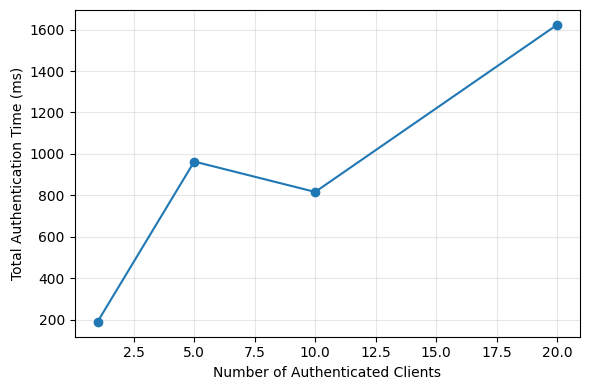

Saved: /content/SBTAuth-FL/results/authentication_scalability.pdf


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.plot(
    summary_scalability[
        "NumberOfClients"
    ],
    summary_scalability[
        "MeanTotal_ms"
    ],
    marker="o"
)

plt.xlabel("Number of Authenticated Clients")
plt.ylabel("Total Authentication Time (ms)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

scalability_plot_path = (
    f"{RESULTS_DIR}/authentication_scalability.pdf"
)

plt.savefig(
    scalability_plot_path,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    scalability_plot_path
)

In [70]:
BC_SCALES = [
    10,
    25,
    50,
    100
]

blockchain_scalability_rows = []

total_registered = 0

for target_count in BC_SCALES:

    additional = (
        target_count
        - total_registered
    )

    registration_times = []

    verification_times = []

    registered_tokens = []

    for i in range(additional):

        unique_index = (
            total_registered + i + 1000
        )

        cred = create_test_credential(
            unique_index,
            "Hospital"
        )

        # -------------------------
        # Registration
        # -------------------------
        start = time.perf_counter()

        tx = contract.functions.registerHospital(
            cred["token"],
            cred["did"],
            cred["owner"],
            cred["vc_hash"],
            cred["pk"],
            cred["expiry"]
        ).transact({
            "from": RA_CHAIN_ACCOUNT
        })

        receipt = \
            w3.eth.wait_for_transaction_receipt(
                tx
            )

        reg_ms = (
            time.perf_counter()
            - start
        ) * 1000

        registration_times.append(
            reg_ms
        )

        registered_tokens.append(
            cred["token"]
        )

    total_registered = target_count

    # -----------------------------
    # Verify newly registered SBTs
    # -----------------------------
    for token in registered_tokens:

        start = time.perf_counter()

        valid, _, _ = \
            contract.functions.verifyHospital(
                token
            ).call()

        verify_ms = (
            time.perf_counter()
            - start
        ) * 1000

        assert valid

        verification_times.append(
            verify_ms
        )

    blockchain_scalability_rows.append({
        "RegisteredCredentials":
            target_count,
        "MeanRegistrationLatency_ms":
            np.mean(registration_times)
            if registration_times
            else np.nan,
        "MeanVerificationLatency_ms":
            np.mean(verification_times)
            if verification_times
            else np.nan
    })

    print(
        f"Credentials={target_count} | "
        f"Register="
        f"{np.mean(registration_times):.2f} ms | "
        f"Verify="
        f"{np.mean(verification_times):.2f} ms"
    )

Credentials=10 | Register=992.77 ms | Verify=23.83 ms
Credentials=25 | Register=252.39 ms | Verify=23.48 ms
Credentials=50 | Register=278.28 ms | Verify=39.35 ms
Credentials=100 | Register=294.93 ms | Verify=24.19 ms


In [71]:
blockchain_scalability = pd.DataFrame(
    blockchain_scalability_rows
)

blockchain_scalability_path = (
    f"{RESULTS_DIR}/blockchain_scalability.csv"
)

blockchain_scalability.to_csv(
    blockchain_scalability_path,
    index=False
)

print(
    "Saved:",
    blockchain_scalability_path
)

display(blockchain_scalability)

Saved: /content/SBTAuth-FL/results/blockchain_scalability.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,RegisteredCredentials,MeanRegistrationLatency_ms,MeanVerificationLatency_ms
0,10,992.774037,23.825970
1,25,252.390357,23.482745
2,50,278.278077,39.345689
3,100,294.926220,24.191092


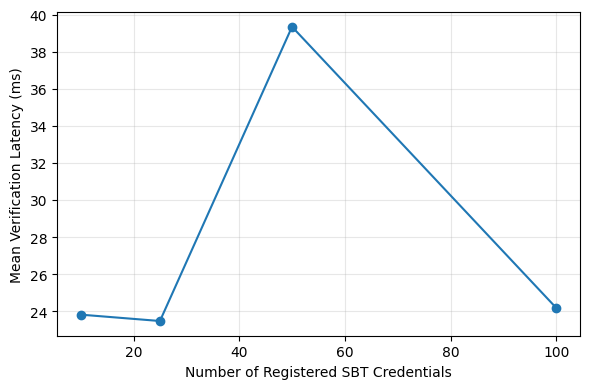

Saved: /content/SBTAuth-FL/results/blockchain_scalability.pdf


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [72]:
plt.figure(figsize=(6, 4))

plt.plot(
    blockchain_scalability[
        "RegisteredCredentials"
    ],
    blockchain_scalability[
        "MeanVerificationLatency_ms"
    ],
    marker="o"
)

plt.xlabel(
    "Number of Registered SBT Credentials"
)

plt.ylabel(
    "Mean Verification Latency (ms)"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()

bc_scale_plot = (
    f"{RESULTS_DIR}/blockchain_scalability.pdf"
)

plt.savefig(
    bc_scale_plot,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    bc_scale_plot
)

In [73]:
storage_rows = []

# Hospital VC stored off-chain
hospital_vc_size = len(
    VC_i_bytes
)

# FLS VC stored off-chain
fls_vc_size = len(
    VC_F_bytes
)

# Logical on-chain Hospital record payload
hospital_onchain_size = (
    len(TokenID_i)       # TokenID
    + len(DID_i)         # DID
    + 20                 # Ethereum owner address
    + len(VC_i_hash)     # Hash(VC)
    + len(pk_i)          # ML-DSA public key
    + 32                 # uint256 expiry
    + 1                  # logical status representation
    + 1                  # logical entity type
)

# Logical on-chain FLS record payload
fls_onchain_size = (
    len(TokenID_F)
    + len(DID_F)
    + 20
    + len(VC_F_hash)
    + len(pk_F)
    + 32
    + 1
    + 1
)

storage_rows.append({
    "Entity": "Hospital",
    "OffChainVC_bytes":
        hospital_vc_size,
    "LogicalOnChainPayload_bytes":
        hospital_onchain_size,
    "PQC_PublicKey_bytes":
        len(pk_i),
    "CredentialHash_bytes":
        len(VC_i_hash)
})

storage_rows.append({
    "Entity": "FLS",
    "OffChainVC_bytes":
        fls_vc_size,
    "LogicalOnChainPayload_bytes":
        fls_onchain_size,
    "PQC_PublicKey_bytes":
        len(pk_F),
    "CredentialHash_bytes":
        len(VC_F_hash)
})

storage_results = pd.DataFrame(
    storage_rows
)

storage_path = (
    f"{RESULTS_DIR}/storage_overhead.csv"
)

storage_results.to_csv(
    storage_path,
    index=False
)

print(
    "Saved:",
    storage_path
)

display(storage_results)

Saved: /content/SBTAuth-FL/results/storage_overhead.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Entity,OffChainVC_bytes,LogicalOnChainPayload_bytes,PQC_PublicKey_bytes,CredentialHash_bytes
0,Hospital,180,1462,1312,32
1,FLS,153,1462,1312,32


In [74]:
SESSION_TESTS = 100

session_rows = []

for run in range(1, SESSION_TESTS + 1):

    # H_i ephemeral key
    a_private, X_test = \
        generate_ecdh_keypair()

    # FLS ephemeral key
    b_private, Y_test = \
        generate_ecdh_keypair()

    # Independent computation
    K_H = ecdh_shared_secret(
        a_private,
        Y_test
    )

    K_F_test = ecdh_shared_secret(
        b_private,
        X_test
    )

    N1_test = random_nonce()
    N2_test = random_nonce()

    SPID_test = H(
        PID_i,
        N1_test
    )

    SK_H_test = H(
        K_H,
        SPID_test,
        TokenID_i,
        TokenID_F,
        X_test,
        Y_test,
        N1_test,
        N2_test
    )

    SK_F_test = H(
        K_F_test,
        SPID_test,
        TokenID_i,
        TokenID_F,
        X_test,
        Y_test,
        N1_test,
        N2_test
    )

    session_rows.append({
        "Run": run,
        "ECDHSecretMatch":
            K_H == K_F_test,
        "SessionKeyMatch":
            SK_H_test == SK_F_test
    })


session_consistency = pd.DataFrame(
    session_rows
)

session_path = (
    f"{RESULTS_DIR}/session_key_consistency.csv"
)

session_consistency.to_csv(
    session_path,
    index=False
)

print(
    "Successful ECDH agreements:",
    session_consistency[
        "ECDHSecretMatch"
    ].sum(),
    "/",
    SESSION_TESTS
)

print(
    "Successful session-key agreements:",
    session_consistency[
        "SessionKeyMatch"
    ].sum(),
    "/",
    SESSION_TESTS
)

print("Saved:", session_path)

Successful ECDH agreements: 100 / 100
Successful session-key agreements: 100 / 100
Saved: /content/SBTAuth-FL/results/session_key_consistency.csv


In [75]:
import os

all_results = sorted(
    os.listdir(RESULTS_DIR)
)

print("Current results/")
print("==============================")

for filename in all_results:
    print(filename)

Current results/
authentication_latency.csv
authentication_scalability.csv
authentication_scalability.pdf
blockchain_overhead.csv
blockchain_scalability.csv
blockchain_scalability.pdf
communication_overhead.csv
crypto_benchmark.csv
fl_results.csv
security_attack_results.csv
session_key_consistency.csv
storage_overhead.csv


In [76]:
I have this files now:

SyntaxError: invalid syntax (2395268138.py, line 1)

In [77]:
from pathlib import Path
import os
import shutil
import json
import sys

PROJECT_DIR = Path("/content/SBTAuth-FL")
SRC_DIR = PROJECT_DIR / "src"
EXP_DIR = PROJECT_DIR / "experiments"
RESULTS_DIR = PROJECT_DIR / "results"
CONTRACT_DIR = PROJECT_DIR / "contracts"

for folder in [
    PROJECT_DIR,
    SRC_DIR,
    EXP_DIR,
    RESULTS_DIR,
    CONTRACT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Existing result files:")

existing_results = sorted(
    p.name for p in RESULTS_DIR.iterdir()
    if p.is_file()
)

for f in existing_results:
    print("  ✓", f)

Project directory: /content/SBTAuth-FL
Existing result files:
  ✓ authentication_latency.csv
  ✓ authentication_scalability.csv
  ✓ authentication_scalability.pdf
  ✓ blockchain_overhead.csv
  ✓ blockchain_scalability.csv
  ✓ blockchain_scalability.pdf
  ✓ communication_overhead.csv
  ✓ crypto_benchmark.csv
  ✓ fl_results.csv
  ✓ security_attack_results.csv
  ✓ session_key_consistency.csv
  ✓ storage_overhead.csv


In [78]:
%%writefile /content/SBTAuth-FL/src/__init__.py
"""
SBTAuth-FL reference implementation.

Core components:
- cryptographic utilities
- blockchain registry interaction
- entity registration
- mutual authentication
"""

Overwriting /content/SBTAuth-FL/src/__init__.py


In [79]:
%%writefile /content/SBTAuth-FL/src/crypto_utils.py
from hashlib import sha256
import secrets

from pqcrypto.sign.ml_dsa_44 import (
    keygen as mldsa_keygen,
    sign as mldsa_sign,
    verify as mldsa_verify
)

from cryptography.hazmat.primitives.asymmetric import ec
from cryptography.hazmat.primitives import serialization


def to_bytes(value):
    if isinstance(value, bytes):
        return value

    if isinstance(value, str):
        return value.encode()

    if isinstance(value, int):
        return value.to_bytes(
            max(1, (value.bit_length() + 7) // 8),
            "big"
        )

    raise TypeError(
        f"Unsupported value type: {type(value)}"
    )


def H(*values):
    """
    SHA-256 transcript hash using explicit length separation.
    """
    encoded = b""

    for value in values:
        value = to_bytes(value)

        encoded += (
            len(value).to_bytes(4, "big")
            + value
        )

    return sha256(encoded).digest()


def random_nonce(size=32):
    return secrets.token_bytes(size)


def random_token_id():
    return secrets.token_bytes(32)


def generate_pqc_keypair():
    """
    Generate an ML-DSA-44 signing key pair.
    """
    return mldsa_keygen()


def pqc_sign(secret_key, message):
    return mldsa_sign(
        secret_key,
        message
    )


def pqc_verify(public_key, message, signature):
    try:
        result = mldsa_verify(
            public_key,
            message,
            signature
        )

        return (
            result is None
            or result is True
        )

    except Exception:
        return False


def generate_ecdh_keypair():
    """
    Generate ephemeral P-256 ECDH key pair.
    """
    private_key = ec.generate_private_key(
        ec.SECP256R1()
    )

    public_bytes = (
        private_key.public_key()
        .public_bytes(
            encoding=serialization.Encoding.X962,
            format=serialization.PublicFormat.UncompressedPoint
        )
    )

    return private_key, public_bytes


def ecdh_shared_secret(
    private_key,
    peer_public_bytes
):
    peer_public_key = (
        ec.EllipticCurvePublicKey
        .from_encoded_point(
            ec.SECP256R1(),
            peer_public_bytes
        )
    )

    return private_key.exchange(
        ec.ECDH(),
        peer_public_key
    )

Writing /content/SBTAuth-FL/src/crypto_utils.py


In [80]:
%%writefile /content/SBTAuth-FL/src/blockchain.py
from pathlib import Path

from web3 import Web3
from solcx import (
    compile_standard,
    install_solc
)


SOLC_VERSION = "0.8.24"


def create_test_blockchain():
    """
    Create the local EVM blockchain used in the PoC.

    EthereumTesterProvider is used only to emulate the
    permissioned consortium blockchain behavior required
    by the prototype.
    """
    from web3.providers.eth_tester import (
        EthereumTesterProvider
    )

    w3 = Web3(
        EthereumTesterProvider()
    )

    if not w3.is_connected():
        raise RuntimeError(
            "EthereumTesterProvider connection failed."
        )

    return w3


def compile_contract(
    contract_path,
    solc_version=SOLC_VERSION
):
    install_solc(solc_version)

    contract_path = Path(contract_path)

    source = contract_path.read_text()

    compiled = compile_standard(
        {
            "language": "Solidity",
            "sources": {
                contract_path.name: {
                    "content": source
                }
            },
            "settings": {
                "outputSelection": {
                    "*": {
                        "*": [
                            "abi",
                            "evm.bytecode"
                        ]
                    }
                }
            }
        },
        solc_version=solc_version
    )

    contract_data = (
        compiled[
            "contracts"
        ][
            contract_path.name
        ][
            "SBTRegistry"
        ]
    )

    abi = contract_data["abi"]

    bytecode = (
        contract_data[
            "evm"
        ][
            "bytecode"
        ][
            "object"
        ]
    )

    return abi, bytecode


def deploy_registry(
    w3,
    contract_path
):
    abi, bytecode = compile_contract(
        contract_path
    )

    registrar = w3.eth.accounts[0]

    Contract = w3.eth.contract(
        abi=abi,
        bytecode=bytecode
    )

    tx_hash = Contract.constructor().transact(
        {
            "from": registrar
        }
    )

    receipt = (
        w3.eth.wait_for_transaction_receipt(
            tx_hash
        )
    )

    contract = w3.eth.contract(
        address=receipt.contractAddress,
        abi=abi
    )

    return contract, registrar, receipt

Writing /content/SBTAuth-FL/src/blockchain.py


In [81]:
%%writefile /content/SBTAuth-FL/src/registration.py
import json
import secrets
import time

from eth_account import Account

from src.crypto_utils import (
    H,
    random_token_id,
    generate_pqc_keypair
)


def vc_to_bytes(vc):
    """
    Canonical JSON serialization used before hashing
    the demonstrator Verifiable Credential.
    """
    return json.dumps(
        vc,
        sort_keys=True,
        separators=(",", ":")
    ).encode()


def create_hospital_identity(
    hospital_id,
    x_ra,
    role="Healthcare Provider",
    access_level="FL Participant",
    expiry=None
):
    if expiry is None:
        expiry = int(time.time()) + 86400

    pk, sk = generate_pqc_keypair()

    owner_account = Account.create()
    owner = owner_account.address

    did = H(
        hospital_id,
        x_ra
    )

    pid = H(
        did,
        x_ra
    )

    vc = {
        "PID": pid.hex(),
        "Role": role,
        "Hospital": hospital_id,
        "AccessLevel": access_level,
        "Expiry": expiry
    }

    vc_bytes = vc_to_bytes(vc)
    vc_hash = H(vc_bytes)

    token_id = random_token_id()

    return {
        "ID": hospital_id,
        "pk": pk,
        "sk": sk,
        "Owner": owner,
        "DID": did,
        "PID": pid,
        "VC": vc,
        "VC_bytes": vc_bytes,
        "VC_hash": vc_hash,
        "TokenID": token_id,
        "expiry": expiry
    }


def create_fls_identity(
    fls_id,
    x_ra,
    expiry=None
):
    if expiry is None:
        expiry = int(time.time()) + 86400

    pk, sk = generate_pqc_keypair()

    owner_account = Account.create()
    owner = owner_account.address

    did = H(
        fls_id,
        x_ra
    )

    vc = {
        "DID": did.hex(),
        "Role": "Federated Learning Server",
        "AccessLevel": "FL Coordinator",
        "Expiry": expiry
    }

    vc_bytes = vc_to_bytes(vc)
    vc_hash = H(vc_bytes)

    token_id = random_token_id()

    return {
        "ID": fls_id,
        "pk": pk,
        "sk": sk,
        "Owner": owner,
        "DID": did,
        "VC": vc,
        "VC_bytes": vc_bytes,
        "VC_hash": vc_hash,
        "TokenID": token_id,
        "expiry": expiry
    }


def register_hospital(
    contract,
    registrar,
    hospital
):
    tx = contract.functions.registerHospital(
        hospital["TokenID"],
        hospital["DID"],
        hospital["Owner"],
        hospital["VC_hash"],
        hospital["pk"],
        hospital["expiry"]
    ).transact(
        {
            "from": registrar
        }
    )

    return tx


def register_fls(
    contract,
    registrar,
    fls
):
    tx = contract.functions.registerFLS(
        fls["TokenID"],
        fls["DID"],
        fls["Owner"],
        fls["VC_hash"],
        fls["pk"],
        fls["expiry"]
    ).transact(
        {
            "from": registrar
        }
    )

    return tx


def generate_ra_secret():
    return secrets.token_bytes(32)

Writing /content/SBTAuth-FL/src/registration.py


In [82]:
%%writefile /content/SBTAuth-FL/src/authentication.py
from src.crypto_utils import (
    H,
    random_nonce,
    generate_ecdh_keypair,
    ecdh_shared_secret,
    pqc_sign,
    pqc_verify
)


def authenticate(
    contract,
    hospital,
    fls,
    replay_cache=None
):
    """
    Execute one complete SBTAuth-FL mutual
    authentication session.

    Returns:
        success,
        hospital_session_key,
        fls_session_key
    """

    if replay_cache is None:
        replay_cache = set()

    # ==================================================
    # Step 1: Hospital creates ephemeral session values
    # ==================================================

    a_private, X_i = generate_ecdh_keypair()

    N1 = random_nonce()

    SPID_i = H(
        hospital["PID"],
        N1
    )

    # ==================================================
    # Step 2: Hospital creates M1 and ML-DSA signature
    # ==================================================

    M1 = H(
        SPID_i,
        hospital["TokenID"],
        X_i,
        N1
    )

    sigma_i = pqc_sign(
        hospital["sk"],
        M1
    )

    # ==================================================
    # Step 3: FLS verifies SBT and hospital signature
    # ==================================================

    valid_hospital, registered_pk_i, _ = (
        contract.functions.verifyHospital(
            hospital["TokenID"]
        ).call()
    )

    if not valid_hospital:
        return False, None, None

    if N1.hex() in replay_cache:
        return False, None, None

    if not pqc_verify(
        registered_pk_i,
        M1,
        sigma_i
    ):
        return False, None, None

    replay_cache.add(
        N1.hex()
    )

    # ==================================================
    # Step 4: FLS creates its ephemeral values
    # ==================================================

    b_private, Y_F = generate_ecdh_keypair()

    N2 = random_nonce()

    K_F = ecdh_shared_secret(
        b_private,
        X_i
    )

    # ==================================================
    # Step 5: FLS generates M2
    # ==================================================

    M2 = H(
        fls["DID"],
        fls["TokenID"],
        SPID_i,
        X_i,
        Y_F,
        N1,
        N2
    )

    sigma_F = pqc_sign(
        fls["sk"],
        M2
    )

    # ==================================================
    # Step 6: Hospital verifies FLS SBT
    # ==================================================

    valid_fls, registered_pk_f, _ = (
        contract.functions.verifyFLS(
            fls["DID"],
            fls["TokenID"]
        ).call()
    )

    if not valid_fls:
        return False, None, None

    expected_M2 = H(
        fls["DID"],
        fls["TokenID"],
        SPID_i,
        X_i,
        Y_F,
        N1,
        N2
    )

    if expected_M2 != M2:
        return False, None, None

    if not pqc_verify(
        registered_pk_f,
        M2,
        sigma_F
    ):
        return False, None, None

    # ==================================================
    # Step 7: Hospital derives ECDH shared secret
    # ==================================================

    K_i = ecdh_shared_secret(
        a_private,
        Y_F
    )

    # ==================================================
    # Step 8: Both sides derive session key
    # ==================================================

    SK_i = H(
        K_i,
        SPID_i,
        hospital["TokenID"],
        fls["TokenID"],
        X_i,
        Y_F,
        N1,
        N2
    )

    SK_F = H(
        K_F,
        SPID_i,
        hospital["TokenID"],
        fls["TokenID"],
        X_i,
        Y_F,
        N1,
        N2
    )

    success = (
        SK_i == SK_F
    )

    return success, SK_i, SK_F

Writing /content/SBTAuth-FL/src/authentication.py


In [83]:
!python -m py_compile \
    /content/SBTAuth-FL/src/crypto_utils.py \
    /content/SBTAuth-FL/src/blockchain.py \
    /content/SBTAuth-FL/src/registration.py \
    /content/SBTAuth-FL/src/authentication.py

print("✓ Core source files compile successfully.")

✓ Core source files compile successfully.


In [84]:
%%writefile /content/SBTAuth-FL/experiments/README.md
# SBTAuth-FL Experiments

The complete evaluated experiment workflow is provided in:

`../SBTAuth_FL_PoC.ipynb`

The notebook is the canonical executable artifact used to generate the
reported experimental results.

## Experiments

### Cryptographic Benchmark
Measures ML-DSA-44 key generation, signing and verification, ECDH
operations, and SHA-256 transcript hashing.

Output:

`../results/crypto_benchmark.csv`

### Authentication Latency
Measures the end-to-end two-message SBTAuth-FL authentication protocol,
including smart-contract verification, ML-DSA signature verification,
ECDH, and session-key establishment.

Output:

`../results/authentication_latency.csv`

### Communication Overhead
Measures the actual serialized field sizes of protocol messages M1 and M2,
including ML-DSA-44 signatures.

Output:

`../results/communication_overhead.csv`

### Blockchain Overhead
Measures smart-contract registration, verification, and revocation
latencies and transaction gas where applicable.

Output:

`../results/blockchain_overhead.csv`

### Authentication Scalability
Measures authentication latency as the number of participating clients
increases.

Outputs:

`../results/authentication_scalability.csv`

`../results/authentication_scalability.pdf`

### Blockchain Scalability
Measures smart-contract credential-verification behavior as the number
of registered credentials increases.

Outputs:

`../results/blockchain_scalability.csv`

`../results/blockchain_scalability.pdf`

### Security Attack Validation
Evaluates implemented attack cases including hospital impersonation,
FLS impersonation, transcript tampering, replay, and invalid SBT TokenID.

Output:

`../results/security_attack_results.csv`

### Session-Key Consistency
Repeatedly verifies that the hospital and FLS independently derive the
same ECDH shared secret and final session key.

Output:

`../results/session_key_consistency.csv`

### Storage Overhead
Reports the logical credential payload sizes used by the PoC.

Output:

`../results/storage_overhead.csv`

### Federated Learning Experiment
Runs authenticated federated learning using MNIST and FedAvg.

Output:

`../results/fl_results.csv`

## Important

The security attack experiments constitute implementation-level validation
of the tested attack cases. They are not a substitute for formal
cryptographic security analysis.

The local EthereumTesterProvider deployment emulates the blockchain
functionality required by the proof of concept; it should not be
interpreted as a performance model of a production consortium network.

Writing /content/SBTAuth-FL/experiments/README.md


In [85]:
%%writefile /content/SBTAuth-FL/experiments/protocol_smoke_test.py
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

from src.blockchain import (
    create_test_blockchain,
    deploy_registry
)

from src.registration import (
    generate_ra_secret,
    create_hospital_identity,
    create_fls_identity,
    register_hospital,
    register_fls
)

from src.authentication import authenticate


def main():

    contract_path = (
        ROOT
        / "contracts"
        / "SBTRegistry.sol"
    )

    w3 = create_test_blockchain()

    contract, registrar, _ = (
        deploy_registry(
            w3,
            contract_path
        )
    )

    x_ra = generate_ra_secret()

    hospital = create_hospital_identity(
        "Hospital-A",
        x_ra
    )

    fls = create_fls_identity(
        "Federated-Learning-Server",
        x_ra
    )

    tx_h = register_hospital(
        contract,
        registrar,
        hospital
    )

    w3.eth.wait_for_transaction_receipt(
        tx_h
    )

    tx_f = register_fls(
        contract,
        registrar,
        fls
    )

    w3.eth.wait_for_transaction_receipt(
        tx_f
    )

    success, sk_h, sk_f = authenticate(
        contract,
        hospital,
        fls
    )

    assert success
    assert sk_h == sk_f

    print(
        "SBTAuth-FL protocol smoke test: PASS"
    )


if __name__ == "__main__":
    main()

Writing /content/SBTAuth-FL/experiments/protocol_smoke_test.py


In [86]:
!cd /content/SBTAuth-FL && python experiments/protocol_smoke_test.py

SBTAuth-FL protocol smoke test: PASS
<sys>:0: ResourceWarning: unclosed file <_io.TextIOWrapper name='/tmp/.solcx-lock-0.8.24' mode='w' encoding='utf-8'>


In [87]:
%%writefile /content/SBTAuth-FL/requirements.txt
web3[tester]
py-solc-x
pqcrypto
cryptography
numpy
pandas
matplotlib
torch
torchvision

Overwriting /content/SBTAuth-FL/requirements.txt


In [88]:
import subprocess

packages = [
    "web3",
    "eth-tester",
    "py-solc-x",
    "pqcrypto",
    "cryptography",
    "numpy",
    "pandas",
    "matplotlib",
    "torch",
    "torchvision"
]

with open(
    "/content/SBTAuth-FL/environment.txt",
    "w"
) as f:

    f.write(
        f"Python: {sys.version}\n\n"
    )

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "freeze"
        ],
        stdout=f,
        text=True
    )

print("✓ environment.txt created")

✓ environment.txt created


In [89]:
%%writefile /content/SBTAuth-FL/.gitignore
__pycache__/
*.pyc
*.pyo

.ipynb_checkpoints/

data/
datasets/
MNIST/

.DS_Store
Thumbs.db

*.log

.env
.env.*

Writing /content/SBTAuth-FL/.gitignore


In [90]:
%%writefile /content/SBTAuth-FL/README.md
# SBTAuth-FL

Proof-of-concept implementation and experimental artifact for:

**SBTAuth-FL: A Blockchain-Assisted Anonymous Authentication Protocol Using Soulbound Tokens for Secure Healthcare Federated Learning**

## Overview

SBTAuth-FL provides blockchain-assisted authentication for healthcare
federated learning participants using non-transferable Soulbound Token
(SBT) credential bindings.

The proof of concept integrates:

- Solidity smart contracts
- Web3.py
- EthereumTesterProvider
- ML-DSA-44 digital signatures
- P-256 ephemeral ECDH
- SHA-256 transcript hashing
- PyTorch federated learning
- MNIST
- FedAvg

ML-DSA-44 is used for entity authentication. The current prototype uses
classical P-256 ECDH for session-key establishment and therefore does not
claim full post-quantum key establishment.

## Architecture

A trusted Registration Authority (RA) is used only during initial entity
registration.

For each authorized hospital, the smart contract records the SBT
credential binding, including:

- TokenID
- DID
- registered blockchain owner address
- hash of the Verifiable Credential
- ML-DSA public key
- validity status
- expiry information

The full Verifiable Credential is maintained off-chain.

During routine authentication, the RA is not contacted.

The hospital and Federated Learning Server perform a two-message mutual
authentication protocol. Each party verifies the counterparty's
blockchain-registered credential and ML-DSA signature before deriving an
ECDH shared secret and session key.

## Repository Structure

```text
SBTAuth-FL/
├── SBTAuth_FL_PoC.ipynb
├── README.md
├── requirements.txt
├── environment.txt
├── contracts/
│   └── SBTRegistry.sol
├── src/
│   ├── __init__.py
│   ├── crypto_utils.py
│   ├── blockchain.py
│   ├── registration.py
│   └── authentication.py
├── experiments/
│   ├── README.md
│   └── protocol_smoke_test.py
└── results/

Writing /content/SBTAuth-FL/README.md


In [91]:
expected_results = [
    "authentication_latency.csv",
    "authentication_scalability.csv",
    "authentication_scalability.pdf",
    "blockchain_overhead.csv",
    "blockchain_scalability.csv",
    "blockchain_scalability.pdf",
    "communication_overhead.csv",
    "crypto_benchmark.csv",
    "fl_results.csv",
    "security_attack_results.csv",
    "session_key_consistency.csv",
    "storage_overhead.csv",
]

print("RESULT FILE CHECK")
print("=" * 50)

missing_results = []

for filename in expected_results:

    path = RESULTS_DIR / filename

    if path.exists():
        print(
            "✓",
            filename,
            f"({path.stat().st_size} bytes)"
        )
    else:
        print(
            "✗ MISSING:",
            filename
        )

        missing_results.append(
            filename
        )

print()

if not missing_results:
    print(
        "✓ All expected result files are present."
    )
else:
    print(
        "Missing:",
        missing_results
    )

RESULT FILE CHECK
✓ authentication_latency.csv (2144 bytes)
✓ authentication_scalability.csv (1840 bytes)
✓ authentication_scalability.pdf (13466 bytes)
✓ blockchain_overhead.csv (2446 bytes)
✓ blockchain_scalability.csv (234 bytes)
✓ blockchain_scalability.pdf (15107 bytes)
✓ communication_overhead.csv (497 bytes)
✓ crypto_benchmark.csv (624 bytes)
✓ fl_results.csv (2292 bytes)
✓ security_attack_results.csv (267 bytes)
✓ session_key_consistency.csv (1328 bytes)
✓ storage_overhead.csv (140 bytes)

✓ All expected result files are present.
